## Tony Grove: Raw NLDAS and CM
Analysis of model output using raw NLDAS forcings and the CM version of the snow model.

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from buildforcing.datasets import PNNLSnotel

In [2]:
# Run configuration
site = 'tonygrovers'
spin_up = '100y'
forcings = 's00000000'
forcing_build = 'v0.4.4'
run_config = 'v0'

Load the 'Land Daily' diagnostic from output.

In [3]:
folder_path = f'C:/Users/clmbn/NMT_PhD/data/output/{site}/{site}_{forcings}_{forcing_build}_{run_config}/history/'
land_daily = xr.open_dataset(folder_path + '20091001.land_daily.nc')

In [7]:
land_daily

<xarray.Dataset> Size: 2MB
Dimensions:                  (grid_index: 1, time: 4382, nv: 2, lon: 1,
                              lonb: 2, lat: 1, latb: 2, zfull_soil: 20,
                              zhalf_soil: 21, band: 2)
Coordinates:
  * grid_index               (grid_index) float64 8B 0.0
  * time                     (time) object 35kB 2009-10-01 12:00:00 ... 2021-...
  * nv                       (nv) float64 16B 1.0 2.0
  * lon                      (lon) float64 8B -111.6
  * lonb                     (lonb) float64 16B -112.1 -111.1
  * lat                      (lat) float64 8B 41.89
  * latb                     (latb) float64 16B 41.39 42.39
  * zfull_soil               (zfull_soil) float64 160B 0.01 0.04 ... 6.75 8.75
  * zhalf_soil               (zhalf_soil) float64 168B 0.0 0.02 ... 7.5 10.0
  * band                     (band) float64 16B 1.0 2.0
    geolon_t                 (grid_index) float64 8B ...
    geolat_t                 (grid_index) float64 8B ...
Data variables: (12/56)
    fco2                     (time, grid_index) float32 18kB ...
    t_ref                    (time, grid_index) float32 18kB ...
    co2_mol_flux             (time, grid_index) float32 18kB ...
    co2_mol_flux1            (time, grid_index) float32 18kB ...
    btot                     (time, grid_index) float32 18kB ...
    Ctot                     (time, grid_index) float32 18kB ...
    ...                       ...
    drydep_md                (time, grid_index) float32 18kB ...
    drydep_om                (time, grid_index) float32 18kB ...
    average_T1               (time) datetime64[ns] 35kB ...
    average_T2               (time) datetime64[ns] 35kB ...
    average_DT               (time) timedelta64[ns] 35kB ...
    time_bnds                (time, nv) object 70kB ...
Attributes:
    filename:          land_daily.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

In [6]:
# Extract snow data from Land Daily dataset
snow_data = land_daily[['snow','snow_depth','snow_density']].isel(grid_index=0).to_dataframe()
snow_data.index = snow_data.index.to_datetimeindex()

# Convert index to America/Denver timezone
snow_data.index = snow_data.index.tz_localize('UTC').tz_convert('America/Denver')

C:\Users\clmbn\AppData\Local\Temp\ipykernel_11876\4214117964.py:3: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  snow_data.index = snow_data.index.to_datetimeindex()


Load the Snotel data

In [4]:
snotel = PNNLSnotel('Tony Grove RS', 'C:/Users/clmbn/NMT_PhD/data/snotel/')

In [8]:
snotel_data = snotel.data

Comparison plots

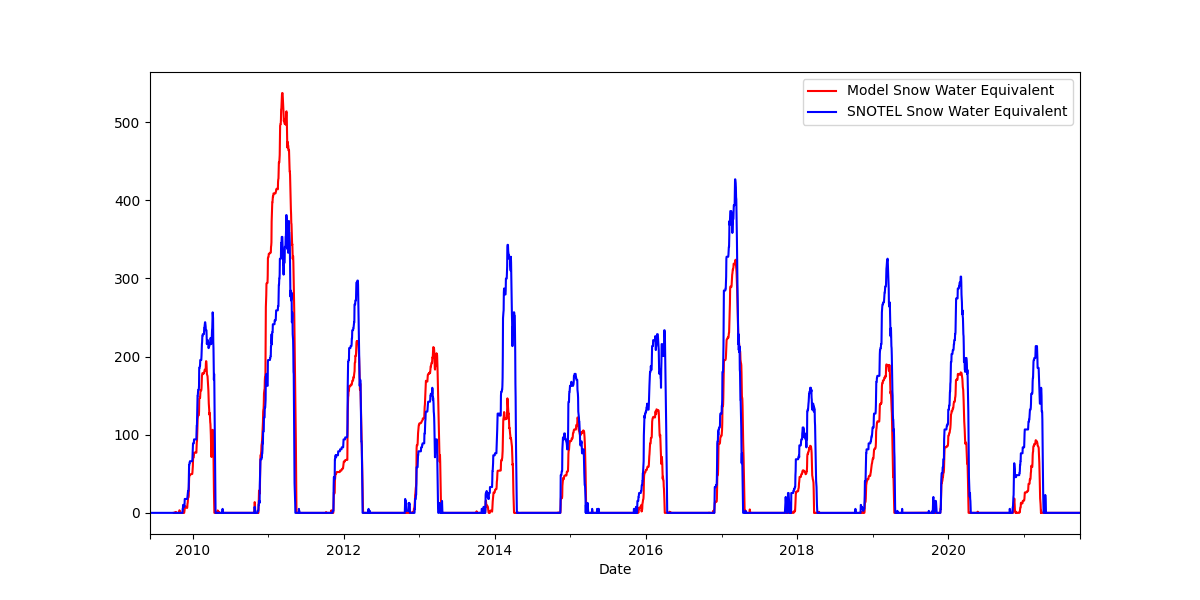

In [12]:
fig, axs = plt.subplots(1, 1, figsize=(12, 6))
snow_data['snow'].plot(ax=axs, label='Model Snow Water Equivalent', color='red')
snotel_data['swe_mm'].plot(ax=axs, label='SNOTEL Snow Water Equivalent', color='blue')
axs.legend()